<a href="https://colab.research.google.com/github/haruki-0226/colab/blob/main/%E7%94%BB%E5%83%8F%E3%83%95%E3%82%A1%E3%82%A4%E3%83%AB_ipynb_%E3%81%AE%E3%82%B3%E3%83%94%E3%83%BC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# セル1：ライブラリのインストール
!pip install -q -U "transformers>=4.57.0" accelerate
#セル2：モジュールのインポート(重要)
import torch
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor
# セル3：モデルのダウンロード・読み込み
MODEL_ID = "Qwen/Qwen3-VL-2B-Instruct"
# Hugging FaceからColabにダウンロード
model = Qwen3VLForConditionalGeneration.from_pretrained(
MODEL_ID,
dtype=torch.float16,
device_map="cuda",
)
processor = AutoProcessor.from_pretrained(MODEL_ID)
model.eval()
print("モデルの読み込み完了")

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

モデルの読み込み完了


Saving cat2.png to cat2.png
画像のサイズ (幅, 高さ)ピクセル: (576, 1024)


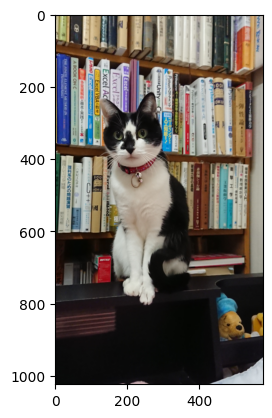

In [ ]:
# セル4：写真のアップロード
from google.colab import files
from PIL import Image, ImageOps
uploaded = files.upload()
image_path = next(iter(uploaded))
img_pil = Image.open(image_path)
img_pil = ImageOps.exif_transpose(img_pil) # スマホ写真の向きを補正
img_pil = img_pil.convert("RGB")
img_pil.thumbnail((1024, 1024)) # 大きな写真は縮小してメモリを節約
print(f"画像のサイズ (幅, 高さ)ピクセル: {img_pil.size}")
plt.imshow(img_pil) # 画像を描かせる
plt.show()

In [ ]:
# セル5：プロンプトを入力して実行
prompt = """この写真に何が写っているか、背景に何が写っているか、日本語で説明してください。"""
messages = [
{
"role": "user",
"content": [
{"type": "image", "image": img_pil},
{"type": "text", "text": prompt},
],
}
]
inputs = processor.apply_chat_template(
 messages,
 tokenize=True,
add_generation_prompt=True,
return_dict=True,
return_tensors="pt",
).to(model.device)

In [ ]:
# 推論モード：学習用の計算（勾配）を記録しないため、メモリ節約と高速化になる
with torch.inference_mode():
    generated_ids = model.generate(**inputs, max_new_tokens=500)
    # generated_ids には「入力（プロンプト）＋回答」がつながって入っている
    # 入力したトークン数を数える
    input_length = inputs["input_ids"].shape[1]
    # 入力の長さより後ろ＝モデルの回答部分だけを取り出す（画像は1枚なので [0]）
    answer_ids = generated_ids[0][input_length:]
    # トークン番号を日本語の文章に戻す（特殊トークンは除く）
    answer = processor.decode(answer_ids, skip_special_tokens=True)
    print(answer)

この写真は、猫が書棚の上に座っている様子を捉えたものです。

背景には、多くの本が整然と並んでいます。その中には、ExcelやVBA、Python、Unifyなどのプログラミングやデータ分析に関する書籍が含まれており、学術的・技術的な内容を含む書籍が多数あります。また、書棚の下には、黄色い帽子をかぶったぬいぐるみが置かれています。
